# Importing all the necessary libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



# Loading the dataset and converting date to datetime format

In [2]:
df = pd.read_csv('data/sri-lanka-daily-port-activity-data-and-shipment-estimates.csv')

df['date'] = pd.to_datetime(df['date'])

print(f"Initial Dataset Shape: {df.shape}")

Initial Dataset Shape: (10824, 29)


#  TASK 1: DATA CLEANING 

## 1. Dropping unnecessary and zero-variance columns

In [3]:
columns_to_drop = ['portid', 'country', 'ISO3']
df = df.drop(columns=columns_to_drop)

## 2. Check for missing values

In [4]:
print("Missing values per column:\n", df.isnull().sum())


Missing values per column:
 date                       0
year                       0
month                      0
day                        0
portname                   0
portcalls_container        0
portcalls_dry_bulk         0
portcalls_general_cargo    0
portcalls_roro             0
portcalls_tanker           0
portcalls_cargo            0
portcalls                  0
import_container           0
import_dry_bulk            0
import_general_cargo       0
import_roro                0
import_tanker              0
import_cargo               0
import                     0
export_container           0
export_dry_bulk            0
export_general_cargo       0
export_roro                0
export_tanker              0
export_cargo               0
export                     0
dtype: int64


## 3. Check for duplicates

In [5]:
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")




Number of duplicate rows: 0


###  If there were missing values or duplicates, we would handle them here. 
### Fortunately, this specific dataset has pre-cleaned of nulls.

# TASK 2: DATA PREPROCESSING (Feature Engineering) 

## 1. Day_Type (Weekend vs Weekday)

In [6]:
df['Day_Type'] = np.where(df['date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')

## 2. Quarter (Seasonality)

In [7]:
df['Quarter'] = 'Q' + df['date'].dt.quarter.astype(str)

## 3. Activity_Level (Low, Normal, High)

In [8]:
p33 = df['portcalls'].quantile(0.33)
p66 = df['portcalls'].quantile(0.66)

def categorize_activity(calls):
    if calls <= p33:
        return 'Low'
    elif calls <= p66:
        return 'Normal'
    else:
        return 'High'

df['Activity_Level'] = df['portcalls'].apply(categorize_activity)

## 4. Dominant_Cargo (Which cargo type had the highest volume that day?)

In [9]:
cargo_columns = [
    'import_container', 'import_dry_bulk', 'import_general_cargo', 
    'import_roro', 'import_tanker'
]
df['Dominant_Cargo'] = df[cargo_columns].idxmax(axis=1)
df['Dominant_Cargo'] = df['Dominant_Cargo'].str.replace('import_', '').str.replace('_', ' ').str.title()
print(f"Initial Dataset Shape: {df.shape}")

Initial Dataset Shape: (10824, 30)


## ENCODING CATEGORICAL VARIABLES

### We used Label Encoding for categorical data

In [10]:
le = LabelEncoder()

## Encoding  categorical columns

In [11]:
categorical_cols = ['portname', 'Day_Type', 'Quarter', 'Activity_Level', 'Dominant_Cargo']
for col in categorical_cols:
    df[col + '_Encoded'] = le.fit_transform(df[col])
# Show the mapping used for each encoded column
for col in categorical_cols:
    print(col, dict(zip(sorted(df[col].unique()), range(df[col].nunique()))))


portname {'Colombo': 0, 'Galle': 1, 'Hambantota': 2, 'Trincomalee': 3}
Day_Type {'Weekday': 0, 'Weekend': 1}
Quarter {'Q1': 0, 'Q2': 1, 'Q3': 2, 'Q4': 3}
Activity_Level {'High': 0, 'Low': 1, 'Normal': 2}
Dominant_Cargo {'Container': 0, 'Dry Bulk': 1, 'General Cargo': 2, 'Roro': 3, 'Tanker': 4}


**Note on Label Encoding:** `LabelEncoder` assigns numbers in alphabetical order, so Weekday = 0, Weekend = 1; Activity_Level: High = 0, Low = 1, Normal = 2.

## --- TRAIN-TEST SPLITTING ---
### This is daily tracking data, so we sorted by date first to prevent data leakage

In [12]:
df = df.sort_values('date')

### Setting 'import' (total import volume) as our target variable (y) for a Regression model
### We used the numerical features and our newly encoded categorical features as (X)

In [13]:
features = [
    'year', 'month', 'day', 'portcalls', 
    'portname_Encoded', 'Day_Type_Encoded', 'Quarter_Encoded', 'Activity_Level_Encoded'
]

X = df[features]
y = df['import'] # THis is our Target variable

## Split sequentially: First 80% for training, last 20% for testing

In [14]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (8659, 8)
Testing data shape: (2165, 8)


 # TASK 3: EXPLORATORY DATA ANALYSIS (EDA)

### Set the visual style for all plots

In [15]:
sns.set_theme(style="whitegrid")

### Visualization 1: Distribution of Total Imports (Target Variable)

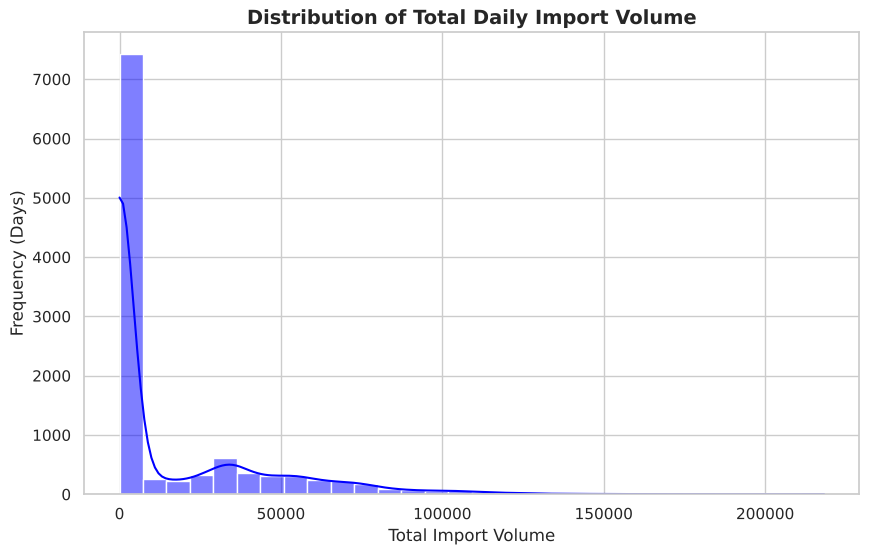

In [16]:
plt.figure(figsize=(10, 6))
sns.histplot(df['import'], bins=30, kde=True, color='blue')
plt.title('Distribution of Total Daily Import Volume', fontsize=14, fontweight='bold')
plt.xlabel('Total Import Volume', fontsize=12)
plt.ylabel('Frequency (Days)', fontsize=12)
plt.show()

### Visualization 2: Activity Level by Port (Using Engineered Feature)

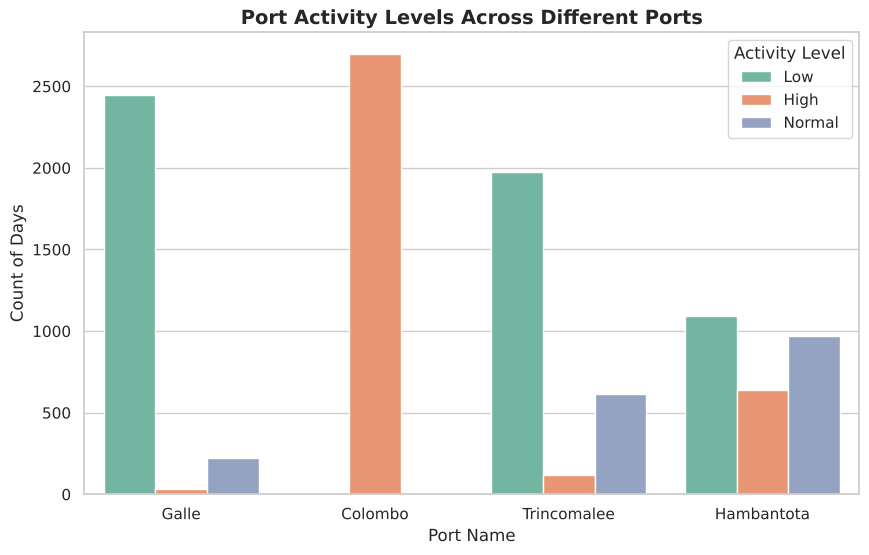

In [17]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='portname', hue='Activity_Level', palette='Set2', 
              order=df['portname'].value_counts().index)
plt.title('Port Activity Levels Across Different Ports', fontsize=14, fontweight='bold')
plt.xlabel('Port Name', fontsize=12)
plt.ylabel('Count of Days', fontsize=12)
plt.legend(title='Activity Level')
plt.show()


### Visualization 3: Trend of Cargo Volume by Quarter (Time-Series)

### Group by Year and Quarter to see the trend And Drawing the plot

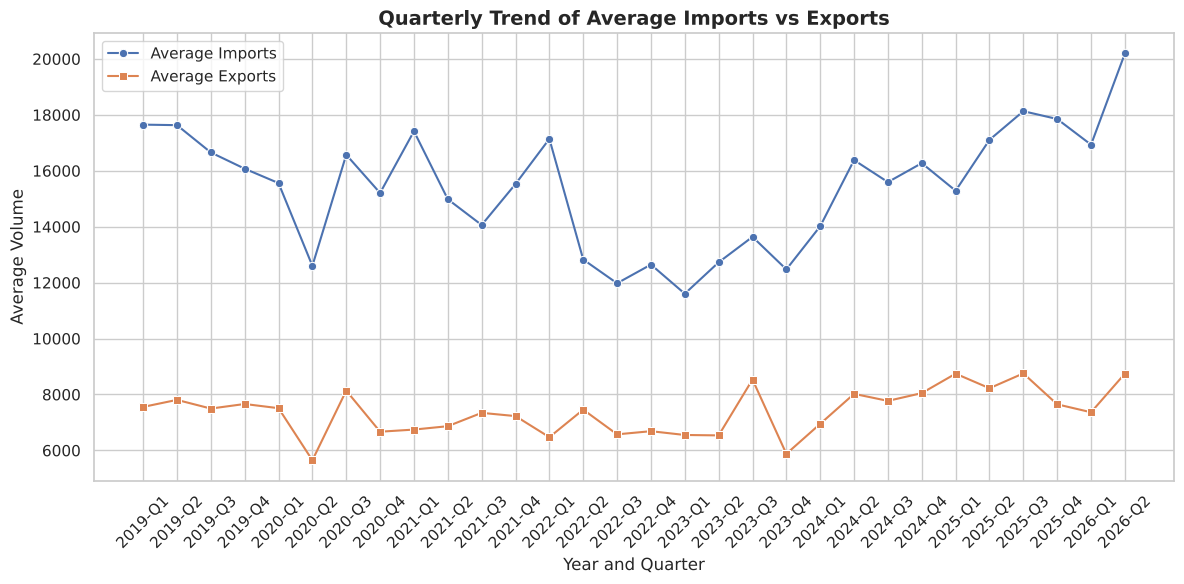

In [18]:

plt.figure(figsize=(12, 6))

quarterly_trend = df.groupby(['year', 'Quarter'])[['import', 'export']].mean().reset_index()
quarterly_trend['Year_Quarter'] = quarterly_trend['year'].astype(str) + '-' + quarterly_trend['Quarter']

sns.lineplot(data=quarterly_trend, x='Year_Quarter', y='import', label='Average Imports', marker='o')
sns.lineplot(data=quarterly_trend, x='Year_Quarter', y='export', label='Average Exports', marker='s')
plt.title('Quarterly Trend of Average Imports vs Exports', fontsize=14, fontweight='bold')
plt.xlabel('Year and Quarter', fontsize=12)
plt.ylabel('Average Volume', fontsize=12)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Visualization 4: Correlation Heatmap for Machine Learning

### Select only numerical columns for the heatmap and creating the Heatmap

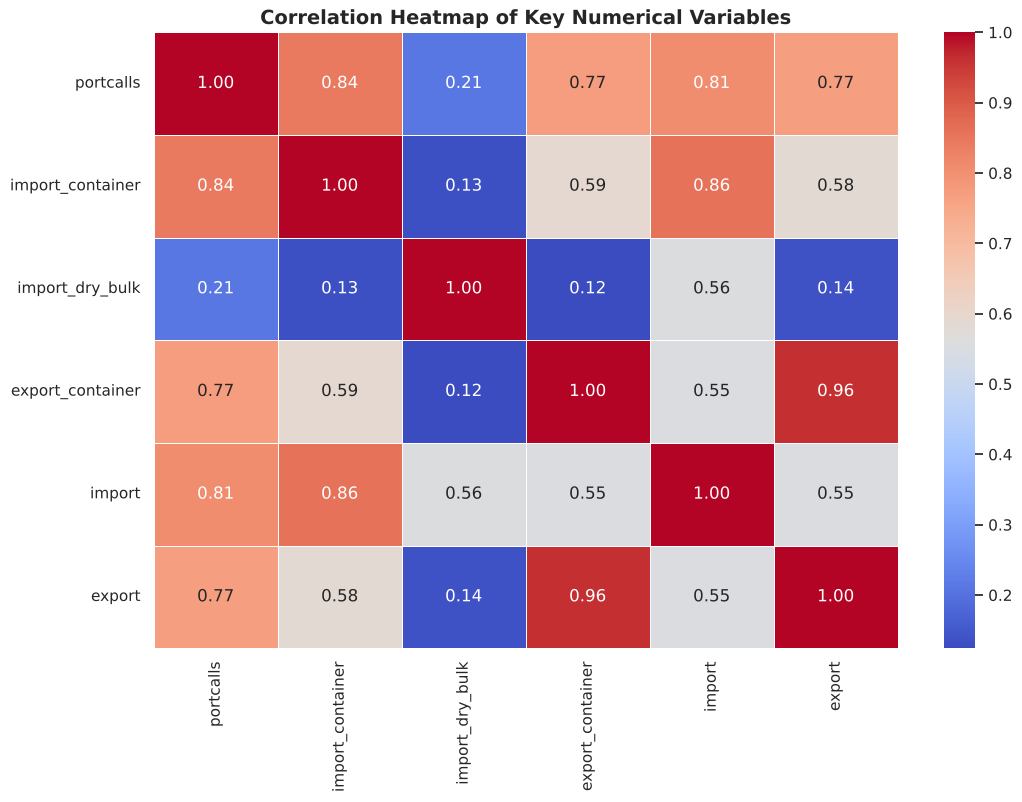

In [19]:
plt.figure(figsize=(12, 8))

numeric_cols = ['portcalls', 'import_container', 'import_dry_bulk', 'export_container', 'import', 'export']
correlation_matrix = df[numeric_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Key Numerical Variables', fontsize=14, fontweight='bold')
plt.show()

# TASK 4: HYPOTHESIS TESTING 

### Set our significance level (alpha)

In [20]:
alpha = 0.05

### TEST 1: Independent Two-Sample T-Test 
### Question: Is there a significant difference in imports between Weekdays and Weekends?

In [21]:
print("--- TEST 1: Independent Two-Sample T-Test ---")

# Isolating the data
weekday_imports = df[df['Day_Type'] == 'Weekday']['import']
weekend_imports = df[df['Day_Type'] == 'Weekend']['import']

# Welch's T-Test (equal_var=False is safer since it is extremely rare for two different groups to have the exact same variance.)
t_stat, p_val_1 = stats.ttest_ind(weekday_imports, weekend_imports, equal_var=False)

print("H0 (Null): There is no significant difference in average daily imports between Weekdays and Weekends.")
print("H1 (Alternative): There is a significant difference in average daily imports between Weekdays and Weekends.")
print(f"p-value: {p_val_1:.5f}")

if p_val_1 < alpha:
    print("Conclusion: Reject the Null Hypothesis. There is a statistically significant difference.")
else:
    print("Conclusion: Fail to reject the Null Hypothesis. There is no statistically significant difference.")


print("\n" + "="*70 + "\n")




--- TEST 1: Independent Two-Sample T-Test ---
H0 (Null): There is no significant difference in average daily imports between Weekdays and Weekends.
H1 (Alternative): There is a significant difference in average daily imports between Weekdays and Weekends.
p-value: 0.01716
Conclusion: Reject the Null Hypothesis. There is a statistically significant difference.




### TEST 2: One-Way ANOVA (Analysis of Variance)
### Question: Does the average import volume change significantly depending on the Quarter (Seasonality)?

In [22]:
print("--- TEST 2: One-Way ANOVA ---")

# Isolating the data for each quarter
q1_imports = df[df['Quarter'] == 'Q1']['import']
q2_imports = df[df['Quarter'] == 'Q2']['import']
q3_imports = df[df['Quarter'] == 'Q3']['import']
q4_imports = df[df['Quarter'] == 'Q4']['import']

# Performing ANOVA test
f_stat, p_val_2 = stats.f_oneway(q1_imports, q2_imports, q3_imports, q4_imports)

print("H0 (Null): The average daily import volume is the same across all four quarters.")
print("H1 (Alternative): At least one quarter has a significantly different average daily import volume.")
print(f"p-value: {p_val_2:.5f}")

if p_val_2 < alpha:
    print("Conclusion: Reject the Null Hypothesis. The quarter (seasonality) significantly impacts import volume.")
else:
    print("Conclusion: Fail to reject the Null Hypothesis. The quarter does not significantly impact import volume.")

--- TEST 2: One-Way ANOVA ---
H0 (Null): The average daily import volume is the same across all four quarters.
H1 (Alternative): At least one quarter has a significantly different average daily import volume.
p-value: 0.88191
Conclusion: Fail to reject the Null Hypothesis. The quarter does not significantly impact import volume.


## TASK 5: MACHINE LEARNING MODELS 

### Model 1: Linear Regression (Baseline Model)

In [23]:
print("--- MODEL 1: Linear Regression ---")

# Initializing and training the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions on test data
lr_predictions = lr_model.predict(X_test)

# Evaluating the model
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_r2 = r2_score(y_test, lr_predictions)

print(f"Mean Absolute Error (MAE): {lr_mae:.2f}")
print(f"Mean Squared Error (MSE): {lr_mse:.2f}")
print(f"R-squared (R2): {lr_r2:.4f}\n")

--- MODEL 1: Linear Regression ---
Mean Absolute Error (MAE): 9673.26
Mean Squared Error (MSE): 326769792.35
R-squared (R2): 0.6186



### Model 2: Random Forest Regressor (Advanced Model)

In [24]:
print("--- MODEL 2: Random Forest Regressor ---")

# Initializing and training the model ( 100 decision trees)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Making predictions on test data
rf_predictions = rf_model.predict(X_test)

# Evaluating the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

print(f"Mean Absolute Error (MAE): {rf_mae:.2f}")
print(f"Mean Squared Error (MSE): {rf_mse:.2f}")
print(f"R-squared (R2): {rf_r2:.4f}\n")

--- MODEL 2: Random Forest Regressor ---


Mean Absolute Error (MAE): 8981.87
Mean Squared Error (MSE): 335380962.23
R-squared (R2): 0.6085



### Feature Importance
This shows which columns the Random Forest relied on most when predicting imports.

--- Random Forest Feature Importance ---


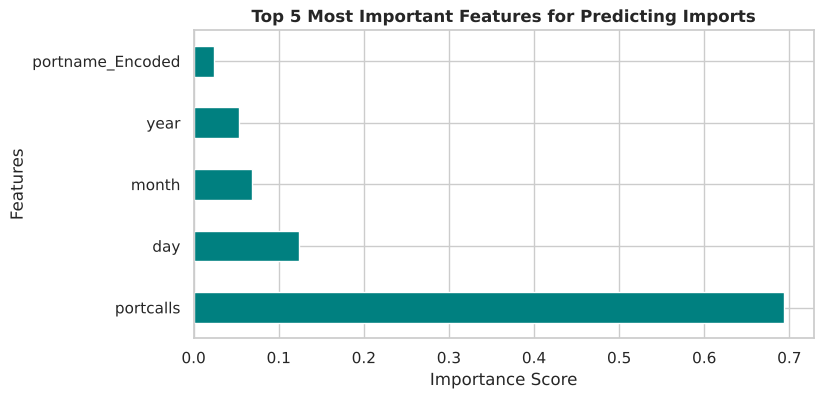

In [25]:
print("--- Random Forest Feature Importance ---")
# This tells which columns are the most useful for predicting imports
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importances.nlargest(5).plot(kind='barh', color='teal', figsize=(8, 4))

plt.title('Top 5 Most Important Features for Predicting Imports', fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

## Conclusion: Model Comparison
| Metric | Linear Regression | Random Forest |
|---|---|---|
| MAE | 9,673.26 | **8,981.87** |
| MSE | **326,769,792** | 335,380,962 |
| R² | **0.6186** | 0.6085 |

Random Forest has the lower MAE, while Linear Regression has the slightly higher R² and lower MSE. **Both models perform similarly (R² ≈ 0.61–0.62)**, so neither is clearly better on every metric.

**Limitations:** `Activity_Level` is derived from `portcalls`, so the two features are partly redundant. Many rows are zero because smaller ports (Trincomalee, Galle) have little activity.